# Credit Card Fraud Detection - Model Comparison

In this notebook, we compare the performance of two machine learning models:

- Logistic Regression
- Decision Tree

We use the ULB Credit Card Fraud dataset to predict whether a transaction is fraudulent (binary classification).

## Step 1: Import Required Libraries
We import common Python libraries for data analysis, machine learning, and evaluation.

In [44]:
# importing libaries
import kagglehub
import shutil
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, 
    precision_score, 
    recall_score,
    average_precision_score
    )

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline

## Step 2: Download the Dataset

We download the ULB Credit Card Fraud dataset from Kaggle using `kagglehub` and copy it into the project's `data/` folder.

**Note:** the `data/` folder is not pushed to GitHub because the file is too large. Running this cell downloads the data automatically, or you can get it manually from [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) and place `creditcard.csv` in `data/`.

In [ ]:
os.makedirs("data", exist_ok=True)
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
shutil.copy(os.path.join(path, "creditcard.csv"), "data/creditcard.csv")

100%|██████████| 66.0M/66.0M [00:33<00:00, 2.04MB/s]

Extracting files...


'data/creditcard.csv'

## Step 3: Load the Dataset
We load the dataset into a pandas dataframe and preview the first few rows

In [3]:
df = pd.read_csv("data/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Step 4: Explore and Understand the data
We check the structure of the data, look for missing values and duplicates and check the class balance in the target variable

In [7]:
# shape of the data
print("Shape:", df.shape)

# columns and their data types
df.info()

Shape: (284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V

In [10]:
# missing values
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [ ]:
# duplicates
print("Duplicates:", df.duplicated().sum())

Duplicates: 1081


In [14]:
# dropping duplicates
df = df.drop_duplicates()
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [17]:
# descriptive stats
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


In [20]:
# class balance in target variable
print(df["Class"].value_counts(normalize=True))

Class
0    0.998333
1    0.001667
Name: proportion, dtype: float64


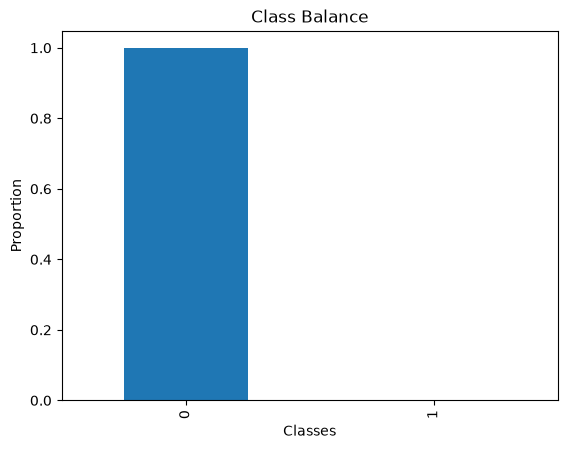

In [24]:
# visualizing the class imbalance
df["Class"].value_counts(normalize=True).plot(kind="bar")
plt.xlabel("Classes")
plt.ylabel("Proportion")
plt.title("Class Balance");

## Step 5: Preprocessing and train test split
- Separate the target vector and the feature matrix
- Split the data into training and test sets
- Scale the `Time` and `Amount` features for better model performance and fair feature contribution

In [26]:
# target vector and feature matrix
target = "Class"
X = df.drop(columns="Class")
y = df[target]

In [27]:
# splitting the data 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [30]:
# scale time and amount columns using a transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("amount", RobustScaler(), ["Amount"]),
        ("time", StandardScaler(), ["Time"])
    ], 
    remainder="passthrough"
)

preprocessor.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('amount', ...), ('time', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fea

## Step 6: Build 2 pipelines for each model
We build 2 pipelines for each model because we will use two techniques to fix the class imbalance.
The two techniques are:
- SMOTE
- Class Weights

In [ ]:
# pipelines (store them in a dictionary as key value pairs)
pipelines = {
    "Logistic + SMOTE": make_pipeline(
        preprocessor,
        SMOTE(random_state=42),
        LogisticRegression(max_iter=1000),
    ),
    "Logistic + Class Weights": make_pipeline(
        preprocessor,
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "Tree + SMOTE": make_pipeline(
        preprocessor,
        SMOTE(random_state=42),
        DecisionTreeClassifier(max_depth=6, random_state=42),
    ),
    "Tree + Class Weights": make_pipeline(
        preprocessor,
        DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    ),
}

In [43]:
# iterating through the dictionary to fit all the models 
# storing the evaluation results in a pandas df

results = []


for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_preds).ravel()
    
    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, y_preds), 4),
        "Recall": round(recall_score(y_test, y_preds), 4),
        "PR-AUC": round(average_precision_score(y_test, probs), 4),
        "Frauds caught": tp,
        "Frauds missed": fn,
        "False alarms": fp,
    })
    
    
results_df = pd.DataFrame(results).set_index("Model")
results_df   

,Precision,Recall,PR-AUC,Frauds caught,Frauds missed,False alarms
Model,,,,,,
Logistic + SMOTE,0.0544,0.8737,0.6747,83,12,1442
Logistic + Class Weights,0.0565,0.8737,0.6721,83,12,1386
Tree + SMOTE,0.0566,0.8316,0.4597,79,16,1316
Tree + Class Weights,0.0680,0.8316,0.4691,79,16,1082


## Conclusion

Among the two models and two imbalance techniques tested:

- **Logistic Regression** performed the best overall:
    - Highest PR-AUC: **0.67** (vs. 0.46-0.47 for the decision tree)
    - Caught the most frauds: **83 of 95** (recall 0.87)
- **Decision Tree** underperformed on ranking:
    - Lower PR-AUC, because a shallow tree produces coarse probability scores
    - Caught fewer frauds (79 of 95), though Tree + Class Weights had the fewest false alarms (1,082) and the best F1 (0.13)
- **SMOTE vs. Class Weights:**
    - Almost identical for Logistic Regression
    - For the Decision Tree, class weights gave about 230 fewer false alarms for the same number of frauds caught, without creating synthetic data
- All pipelines have **low precision (5-7%)**: they catch most fraud but raise many false alarms at the default 0.5 threshold.

Based on this analysis, **Logistic Regression** would be the best model for this dataset and fraud detection task.

Future work could involve:

- Threshold tuning to improve the precision/recall trade-off
- Hyperparameter tuning (e.g., `max_depth`, `C`) with cross-validation
- Trying ensemble models like Random Forest or XGBoost